In [28]:
%pip install -q pandas matplotlib

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

students_df = pd.read_csv('student_data.csv')

Note: you may need to restart the kernel to use updated packages.


In [29]:
students_df.head()

,student_id,name,age,course,score
0,1001,Alice Smith,22,Python,95.0
1,1002,Bob Johnson,19,Data Science,82.0
2,1003,Charlie Williams,24,Web Development,NaN
3,1004,David Brown,23,Machine Learning,91.0
4,1005,Eva Davis,27,Python,65.0


# Data Cleaning and Preparation

## Remove students with missing scores

In [30]:
#drop students with missing scores
students_df = students_df.dropna(subset=['score'])

students_df.head()

,student_id,name,age,course,score
0,1001,Alice Smith,22,Python,95.0
1,1002,Bob Johnson,19,Data Science,82.0
3,1004,David Brown,23,Machine Learning,91.0
4,1005,Eva Davis,27,Python,65.0
5,1006,Frank Miller,20,Data Science,88.0


## Filter students with scores above 80

In [31]:
students_above_80_df = students_df[students_df['score'] > 80]

students_above_80_df

,student_id,name,age,course,score
0,1001,Alice Smith,22,Python,95.0
1,1002,Bob Johnson,19,Data Science,82.0
3,1004,David Brown,23,Machine Learning,91.0
5,1006,Frank Miller,20,Data Science,88.0
9,1010,Jack Anderson,18,Data Science,93.0
11,1012,Leo Jackson,22,Machine Learning,89.0
12,1013,Mia White,20,Python,91.0
14,1015,Olivia Martin,19,Web Development,83.0
16,1017,Quinn Lewis,23,Python,86.0
17,1018,Ruby Clark,21,Data Science,92.0


## Categorize students based on scores

In [32]:

score_categories = {
    'Excellent': (90, 100),
    'Good': (80, 89),
    'Average': (70, 79),
    'Below Average': (0, 69),
}

def categorize_scores(row):
    for category, (low, high) in score_categories.items():
        if low <= row['score'] <= high:
            return category
    return np.nan

students_df['Category'] = students_df.apply(categorize_scores, axis=1)

students_df.head()

,student_id,name,age,course,score,Category
0,1001,Alice Smith,22,Python,95.0,Excellent
1,1002,Bob Johnson,19,Data Science,82.0,Good
3,1004,David Brown,23,Machine Learning,91.0,Excellent
4,1005,Eva Davis,27,Python,65.0,Below Average
5,1006,Frank Miller,20,Data Science,88.0,Good


# Data Analysis

## Average Score by Course

In [33]:
grouped_by_course = students_df.groupby('course')

average_scores = grouped_by_course['score'].mean().reset_index()
average_scores.columns = ['course', 'average_score']
average_scores

,course,average_score
0,Data Science,86.00
1,Machine Learning,84.25
2,Python,83.20
3,Web Development,75.00


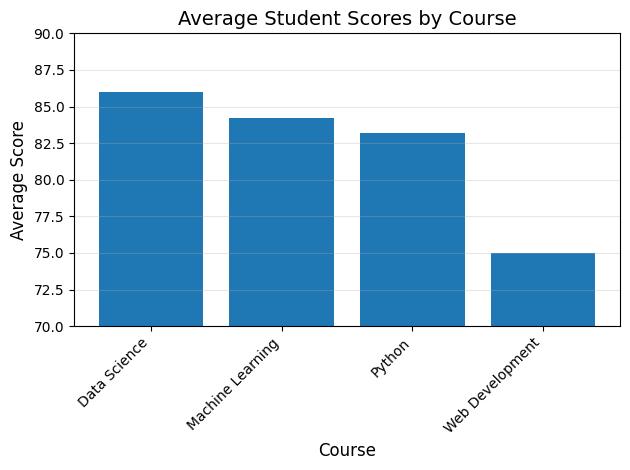

In [46]:
plt.bar(average_scores['course'], average_scores['average_score'])
plt.title('Average Student Scores by Course', fontsize=14)
plt.xlabel('Course', fontsize=12)
plt.ylabel('Average Score', fontsize=12)
plt.ylim(70, 90)
plt.grid(axis='y', alpha=0.3)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

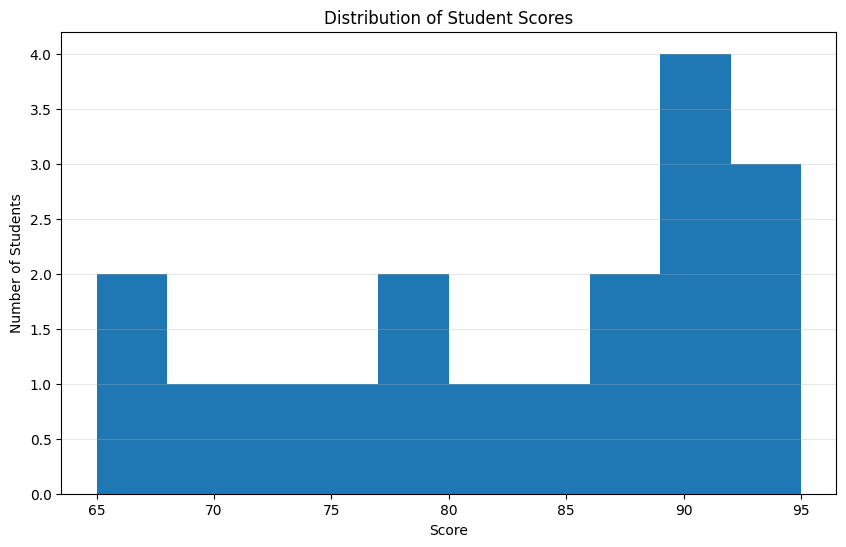

In [45]:
plt.figure(figsize=(10, 6))
plt.hist(students_df['score'], bins=10)
plt.title('Distribution of Student Scores')
plt.xlabel('Score')
plt.ylabel('Number of Students')
plt.grid(axis='y', alpha=0.3)
plt.show()